In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
prices = pd.read_csv(
    "../data/raw/prices.csv",
    index_col=0,
    parse_dates=True
)

prices.head()

,SPY,TLT,GLD,BTC-USD
2015-01-02,169.267517,91.566460,114.080002,315.032013
2015-01-05,166.210602,93.004837,115.800003,274.473999
2015-01-06,164.645096,94.680534,117.120003,286.188995
2015-01-07,166.696762,94.493568,116.430000,294.337006
2015-01-08,169.654785,93.242134,115.940002,283.348999


In [3]:
returns = np.log(
    prices / prices.shift(1)
)

In [4]:
returns = returns.dropna()

In [5]:
returns.head()

,SPY,TLT,GLD,BTC-USD
2015-01-05,-0.018225,0.015586,0.014965,-0.137818
2015-01-06,-0.009463,0.017857,0.011334,0.041796
2015-01-07,0.012384,-0.001977,-0.005909,0.028073
2015-01-08,0.017589,-0.013332,-0.004217,-0.038046
2015-01-09,-0.008046,0.010893,0.011321,0.024607


In [6]:
returns.isna().sum()

SPY        0
TLT        0
GLD        0
BTC-USD    0
dtype: int64

In [7]:
returns.to_csv(
    "data/processed/returns.csv"
)

In [8]:
returns.describe()

,SPY,TLT,GLD,BTC-USD
count,2952.000000,2952.000000,2952.000000,2952.000000
mean,0.000510,-0.000057,0.000408,0.001890
std,0.011068,0.009298,0.010276,0.041592
min,-0.115886,-0.069010,-0.108412,-0.464730
25%,-0.003715,-0.005636,-0.004820,-0.015118
50%,0.000606,0.000311,0.000567,0.001629
75%,0.005909,0.005443,0.005594,0.019610
max,0.099863,0.072503,0.061647,0.225119


In [9]:
annual_mean = returns.mean() * 252

In [10]:
annual_volatility = returns.std() * np.sqrt(252)

In [11]:
summary = pd.DataFrame({
    "Annual Mean": annual_mean,
    "Annual Volatility": annual_volatility,
    "Skewness": returns.skew(),
    "Excess Kurtosis": returns.kurtosis()
})

summary

,Annual Mean,Annual Volatility,Skewness,Excess Kurtosis
SPY,0.128501,0.175701,-0.571640,14.531039
TLT,-0.014273,0.147596,0.003097,4.510614
GLD,0.102907,0.163129,-0.598102,7.291188
BTC-USD,0.476390,0.660260,-0.614710,9.803512


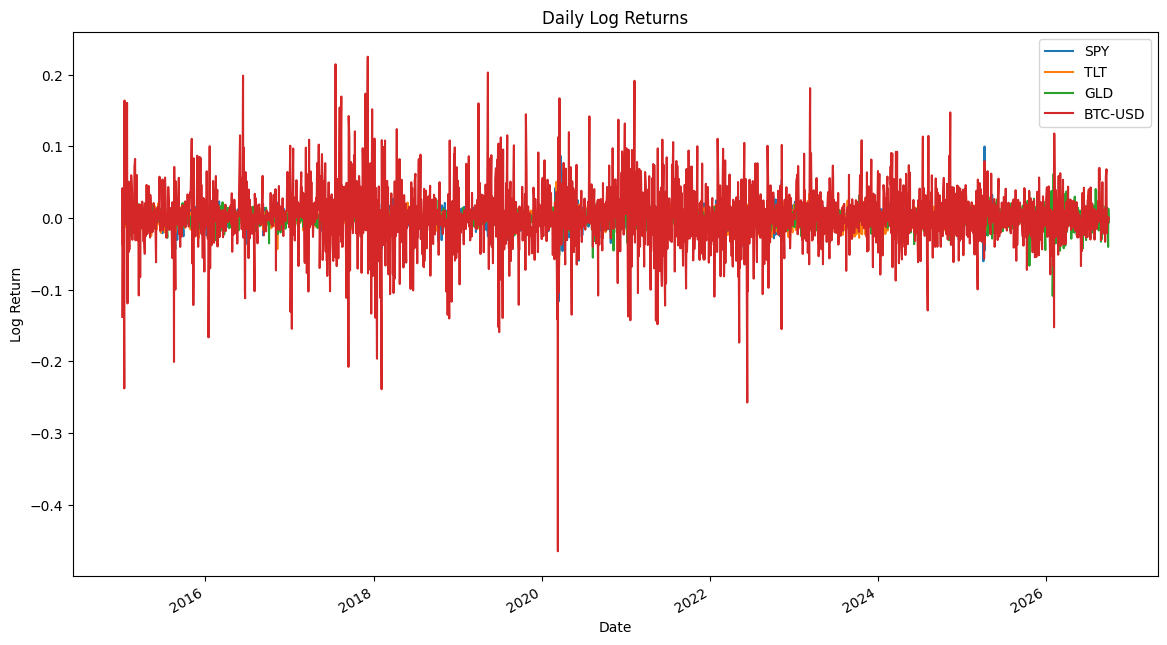

In [12]:
returns.plot(
    figsize=(14, 8),
    title="Daily Log Returns"
)

plt.xlabel("Date")
plt.ylabel("Log Return")
plt.show()

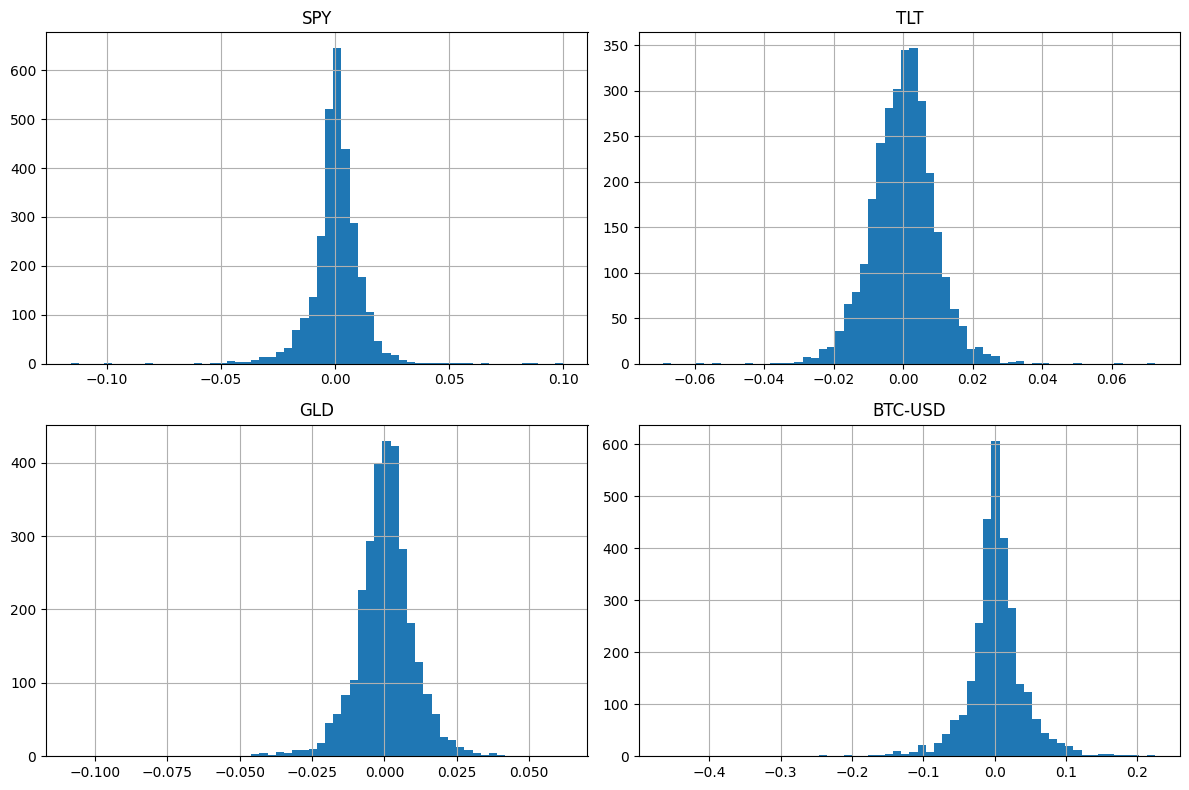

In [13]:
returns.hist(
    bins=60,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

In [14]:
correlation_matrix = returns.corr()

correlation_matrix

,SPY,TLT,GLD,BTC-USD
SPY,1.000000,-0.167060,0.072258,0.244109
TLT,-0.167060,1.000000,0.256601,-0.016290
GLD,0.072258,0.256601,1.000000,0.103744
BTC-USD,0.244109,-0.016290,0.103744,1.000000


In [15]:
rolling_vol = (
    returns.rolling(20).std()
    * np.sqrt(252)
)

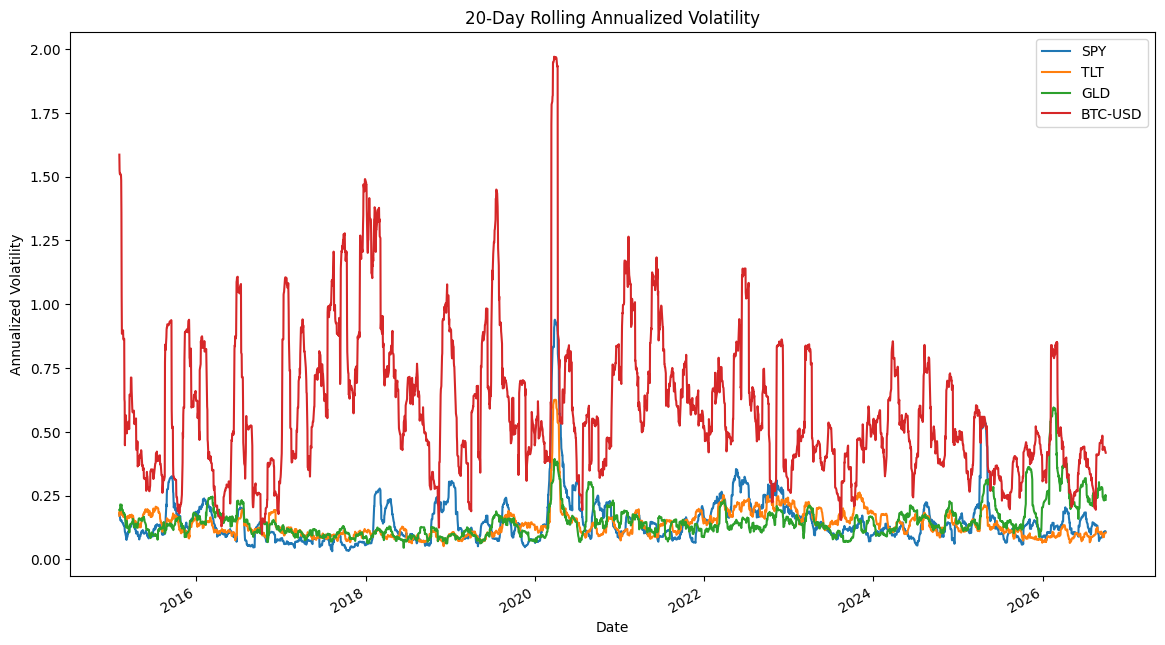

In [16]:
rolling_vol.plot(
    figsize=(14, 8),
    title="20-Day Rolling Annualized Volatility"
)

plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.show()